In [4]:
# ---- Ячейка 1 ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Настройка графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

%matplotlib inline

print("Библиотеки загружены")

Библиотеки загружены


In [2]:
# ---- Ячейка 2 ----
np.random.seed(42)
n = 500

dates = pd.date_range('2023-01-01', periods=n, freq='D')
categories = ['Электроника', 'Одежда', 'Книги', 'Дом', 'Спорт']
regions = ['Москва', 'СПб', 'Казань', 'Новосибирск', 'Екатеринбург']

data = {
    'date': dates,
    'category': np.random.choice(categories, n),
    'region': np.random.choice(regions, n),
    'units_sold': np.random.poisson(lam=30, size=n),
    'price': np.random.normal(loc=2000, scale=500, size=n).clip(500, 5000),
    'discount': np.random.uniform(0, 0.3, size=n),
    'customer_rating': np.random.normal(loc=4.0, scale=0.5, size=n).clip(1, 5)
}
df = pd.DataFrame(data)

df['revenue'] = df['units_sold'] * df['price'] * (1 - df['discount'])
df['price'] = df['price'].round(0)
df['revenue'] = df['revenue'].round(0)
df['customer_rating'] = df['customer_rating'].round(1)

df.head()

,date,category,region,units_sold,price,discount,customer_rating,revenue
0,2023-01-01,Дом,Новосибирск,40,1887.0,0.108070,3.6,67314.0
1,2023-01-02,Спорт,Москва,33,2184.0,0.081118,3.7,66216.0
2,2023-01-03,Книги,Екатеринбург,31,2457.0,0.252814,3.5,56906.0
3,2023-01-04,Спорт,Казань,29,1598.0,0.094004,3.6,41996.0
4,2023-01-05,Спорт,Казань,40,2746.0,0.236680,4.0,83854.0


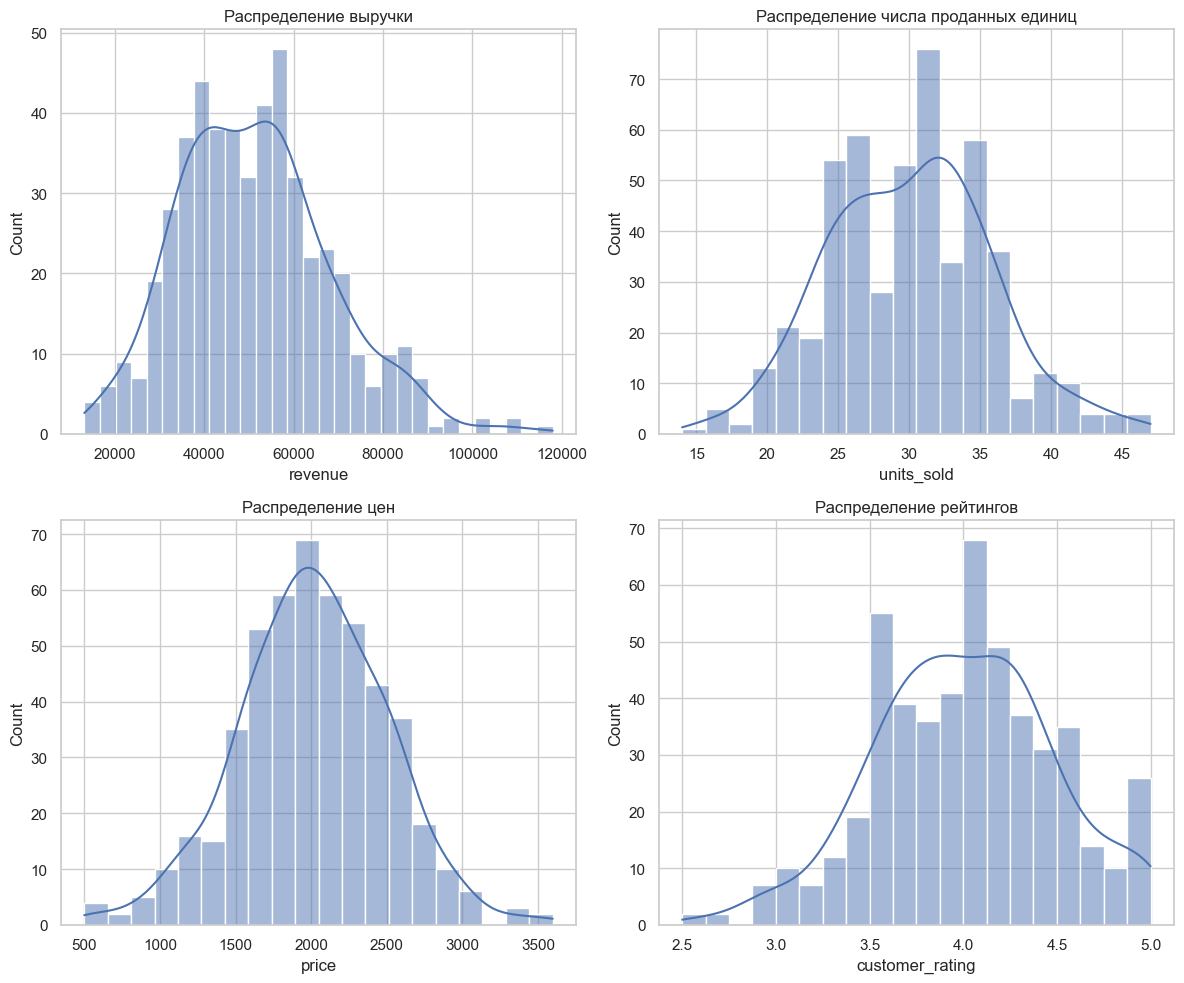

In [5]:
# ---- Ячейка 5 ----
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Выручка
sns.histplot(df['revenue'], bins=30, kde=True, ax=axes[0,0])
axes[0,0].set_title('Распределение выручки')

# Количество продаж
sns.histplot(df['units_sold'], bins=20, kde=True, ax=axes[0,1])
axes[0,1].set_title('Распределение числа проданных единиц')

# Цена
sns.histplot(df['price'], bins=20, kde=True, ax=axes[1,0])
axes[1,0].set_title('Распределение цен')

# Рейтинг
sns.histplot(df['customer_rating'], bins=20, kde=True, ax=axes[1,1])
axes[1,1].set_title('Распределение рейтингов')

plt.tight_layout()
plt.show()

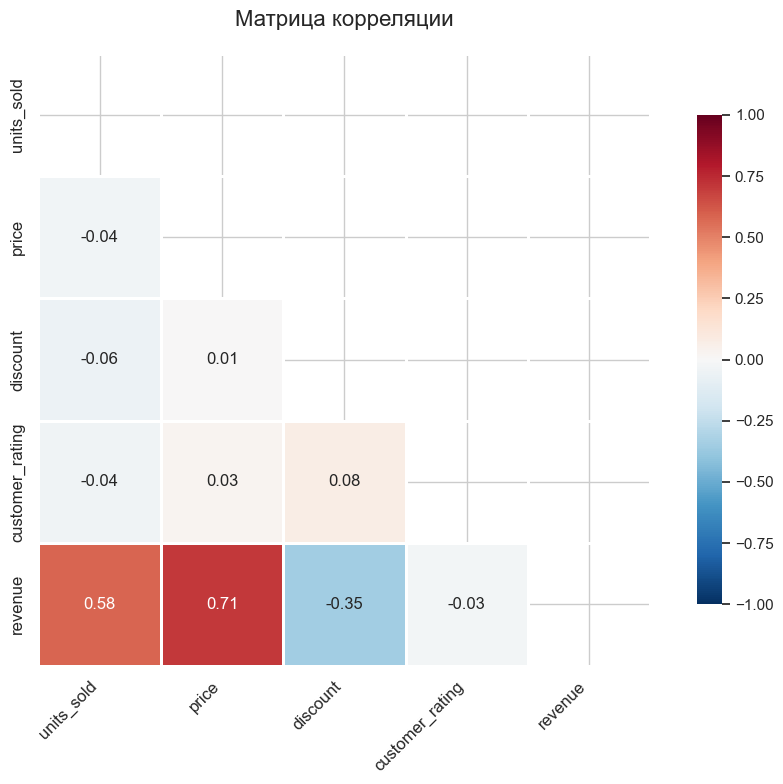

In [6]:
# ---- Ячейка 8 (улучшенная тепловая карта) ----
# Выбираем числовые признаки
numeric_cols = ['units_sold', 'price', 'discount', 'customer_rating', 'revenue']
corr = df[numeric_cols].corr()

# Создаём маску для верхнего треугольника (чтобы не дублировать данные)
mask = np.triu(np.ones_like(corr, dtype=bool))

# Настраиваем размер фигуры
plt.figure(figsize=(10, 8))

# Рисуем тепловую карту с дополнительными параметрами
sns.heatmap(
    corr,
    mask=mask,                # скрываем верхнюю половину
    annot=True,               # показываем числа
    fmt='.2f',                # формат чисел
    cmap='RdBu_r',            # красно-синяя палитра (обратная)
    vmin=-1, vmax=1,          # фиксируем границы для корреляции
    square=True,              # квадратные ячейки
    linewidths=0.8,           # тонкие линии между ячейками
    cbar_kws={"shrink": 0.8}, # уменьшаем цветовую шкалу
    annot_kws={"size": 12}    # размер шрифта аннотаций
)

plt.title('Матрица корреляции', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()